# Gemini Decisions API demo

This notebook shows the Gemini Decisions API (`gemini-decision-1`) step by step.
The API does not generate text. It returns probabilities for typed questions about one shared input.

The scenario is a fictional parcel-delivery company. All data is synthetic.

Before you start, set up `.env` as the README says.

In [1]:
import os
from pathlib import Path

from dotenv import load_dotenv

# The notebook runs in notebooks/. The project root holds .env and data/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(ROOT / ".env")

from decisions_demo.client import DecisionsClient
from decisions_demo.config import load_config

config = load_config(os.environ)
client = DecisionsClient(config)
print(config.describe())

Backend: Gemini Developer API | Decisions model: gemini-decision-1


## 1. One request, three question types

The goal is to classify one email. One request asks a `choice` question (category), a `score` question
(complexity), and four `noul` questions. Expect the category `tracking` with a high probability.

In [2]:
from decisions_demo.render import answers_table
from decisions_demo.scenario import SAMPLE_EMAIL, triage_questions
from rich.console import Console

console = Console()
result = client.decide(SAMPLE_EMAIL, triage_questions())
console.print(answers_table(result))
print(f"Input tokens: {result.input_tokens}, output tokens: {result.output_tokens}, latency: {result.latency_ms:.0f} ms")

                                                      Answers                                                      
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Question            ┃ Type   ┃ Answer                           ┃ Confidence ┃ Distribution                     ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ customer_is_angry   │ noul   │ no (p=0.18)                      │       0.82 │                                  │
│ complexity          │ score  │ 1.30 (level 1: Medium: needs a   │       0.61 │ 0: 0.05, 1: 0.61, 2: 0.35        │
│                     │        │ lookup and a short explanation.) │            │                                  │
│ has_tracking_number │ noul   │ yes (p=0.97)                     │       0.97 │                                  │
│ has_link            │ noul   │ no (p=0.01)                      │       0.99 │                                  │
│ asks_for_money      │ noul   │ no (p=0.01)                      │       0.99 │                                  │
│ category            │ choice │ tracking                         │       1.00 │ tracking 1.00, redelivery 0.00,  │
│                     │        │                                  │            │ damage_claim 0.00                │
└─────────────────────┴────────┴──────────────────────────────────┴────────────┴──────────────────────────────────┘

Input tokens: 543, output tokens: 0, latency: 622 ms


## 2. Branch on the answers

The answers are numbers, so plain code can apply rules. No prompt parsing is necessary.
The rules select a model tier and the next step: `AUTO_REPLY` or `HUMAN_DRAFT`.

In [3]:
from decisions_demo.scenario import decide_triage

decision = decide_triage(result)
print("Category:", decision.category)
print("Model tier:", decision.tier)
print("Next step:", decision.next_step.value)
for reason in decision.reasons:
    print("Reason:", reason)

Category: tracking
Model tier: flash
Next step: AUTO_REPLY
Reason: No rule needs a person. The model tier writes the reply.


## 3. Tool selection

The goal is to select the next tool for an agent. A `choice` question lists six tools and a `none` option.
A `noul` question checks if the email is in scope. Expect `verify_link` for a fake-fee SMS.

In [4]:
from decisions_demo.tools import SAMPLE_TOOL_EMAIL, run_tool, select_tool, tool_questions

result = client.decide(SAMPLE_TOOL_EMAIL, tool_questions())
console.print(answers_table(result))
tool = select_tool(result)
print("Selected tool:", tool)
if tool:
    print(run_tool(tool, "AB123456789XX"))

                                                Answers                                                 
┏━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Question ┃ Type   ┃ Answer       ┃ Confidence ┃ Distribution                                         ┃
┡━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ tool     │ choice │ verify_link  │       1.00 │ verify_link 1.00, none 0.00, explain_import_tax 0.00 │
│ in_scope │ noul   │ yes (p=0.98) │       0.98 │                                                      │
└──────────┴────────┴──────────────┴────────────┴──────────────────────────────────────────────────────┘

Selected tool: verify_link
{'tool': 'verify_link', 'synthetic': True, 'official': False, 'advice': 'Do not pay. The company does not send fee links by SMS.'}


## 4. Multimodal input

The goal is to ask several questions about one image. The code draws a synthetic missed-delivery slip.
Expect "yes" for the slip question and `collect_at_locker` for the next step.

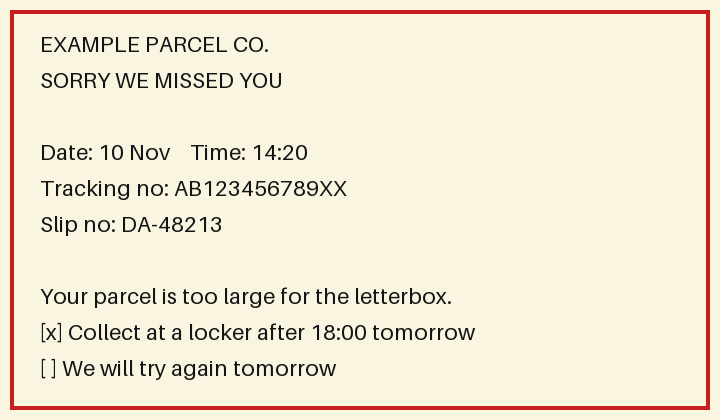

                                                      Answers                                                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Question                ┃ Type   ┃ Answer                         ┃ Confidence ┃ Distribution                   ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ next_step               │ choice │ collect_at_locker              │       0.99 │ collect_at_locker 0.99,        │
│                         │        │                                │            │ wait_for_redelivery 0.01,      │
│                         │        │                                │            │ unclear 0.00                   │
│ is_missed_delivery_slip │ noul   │ yes (p=0.89)                   │       0.89 │                                │
│ tracking_number_visible │ noul   │ yes (p=0.93)                   │       0.93 │                                │
│ legibility              │ score  │ 1.95 (level 2: Fully           │       0.96 │ 0: 0.01, 1: 0.03, 2: 0.96      │
│                         │        │ readable.)                     │            │                                │
└─────────────────────────┴────────┴────────────────────────────────┴────────────┴────────────────────────────────┘

In [5]:
from IPython.display import Image, display

from decisions_demo.client import image_block
from decisions_demo.sample_image import make_delivery_slip, multimodal_questions

png = make_delivery_slip()
display(Image(png))
result = client.decide([image_block(png, "image/png")], multimodal_questions())
console.print(answers_table(result))

## 5. Evaluation on a labeled CSV file

The goal is to measure accuracy. The file `data/sample_emails.csv` has 24 synthetic emails with a label.
The emails are easy, so expect a high accuracy. Use your own CSV file for a real measurement.

In [6]:
from decisions_demo import evaluate

question = evaluate.load_question(ROOT / "data" / "triage_question.json")
labels = list(question["criteria"])
rows = evaluate.load_dataset(ROOT / "data" / "sample_emails.csv", allowed_labels=set(labels))

results = []
for row in rows:
    answer = client.decide(row.query, {evaluate.QUESTION_KEY: question}).answers[evaluate.QUESTION_KEY]
    results.append(evaluate.RowResult(row.query, row.label, answer.choice, answer.confidence, answer.probabilities))

metrics = evaluate.compute_metrics(results, labels)
print(f"Accuracy: {metrics.accuracy:.1%} of {metrics.total} rows")
print("Mean confidence, correct rows:", metrics.mean_confidence_correct)
for r in results:
    if not r.correct:
        print("Wrong:", r.label, "->", r.predicted, "|", r.query)

Accuracy: 100.0% of 24 rows
Mean confidence, correct rows: 0.9869305115596875


## 6. Comparison with generateContent

The goal is to compare the same questions through one `generateContent` call with a JSON schema.
The table shows latency and tokens. The costs are estimates from the price table in `compare.py`.

In [7]:
from google import genai

from decisions_demo import compare

genai_client = genai.Client(api_key=config.api_key, http_options={"timeout": 60_000})
model = config.tier_models["lite"]
email = SAMPLE_EMAIL
decision_result = client.decide(email, triage_questions())
generated = compare.run_generate(genai_client, model, email, triage_questions())

for name, mdl, latency, tin, tout in [
    ("Decisions API", config.decisions_model, decision_result.latency_ms, decision_result.input_tokens, 0),
    ("generateContent", model, generated.latency_ms, generated.input_tokens, generated.output_tokens),
]:
    cost = compare.estimate_cost(mdl, tin, tout)
    print(f"{name:16} {mdl:24} {latency:8.0f} ms  in={tin:5}  out={tout:4}  estimated US$ {cost}")
print("generateContent answers:", generated.answers)

Decisions API    gemini-decision-1             419 ms  in=  543  out=   0  estimated US$ 5.4300000000000005e-05
generateContent  gemini-3.5-flash-lite        5846 ms  in=  333  out=  60  estimated US$ 0.0002499
generateContent answers: {'category': 'tracking', 'complexity': 1, 'has_tracking_number': True, 'has_link': False, 'asks_for_money': False, 'customer_is_angry': True}


## Next step: the ADK agent

Part 2 of the demo is an ADK agent in `decisions_agent/`. Start it from the project root with `adk web`.
The README explains the router and the model-tier callback.